# Modell-Evaluierung (Pipeline mit PCA & Logistischer Regression)
Analyse der Vorhersagen, Feature Importance der Hauptkomponenten und Overfitting-Analyse basierend auf den GridSearchCV-Ergebnissen.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import learning_curve

sns.set_theme(style="darkgrid")

In [9]:
data_dir = Path("data")
model_dir = Path("saved_models")

# Daten laden
X_train = np.load(data_dir / "train" / "X_train.npy")
y_train = np.load(data_dir / "train" / "y_train.npy")
X_test = np.load(data_dir / "eval" / "X_test.npy")
y_test = np.load(data_dir / "eval" / "y_test.npy")

# Bestes Modell und CV-Resultate laden
model = joblib.load(model_dir / "best_logistic_regression.pkl")
results = pd.read_pickle(model_dir / "cv_results.pkl")

print(f"Daten geladen. Trainings-Pixel: {X_train.shape[0]} | Test-Pixel: {X_test.shape[0]}")

Daten geladen. Trainings-Pixel: 48000 | Test-Pixel: 12000


In [10]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"Accuracy (Train): {acc_train * 100:.2f} %")
print(f"Accuracy (Test):  {acc_test * 100:.2f} %")
print(f"Overfitting Gap:  {abs(acc_train - acc_test) * 100:.4f} Prozentpunkte\n")
print(classification_report(y_test, y_pred_test, target_names=['Intakt (0)', 'Defekt (1)']))

Accuracy (Train): 98.98 %
Accuracy (Test):  98.81 %
Overfitting Gap:  0.1708 Prozentpunkte

              precision    recall  f1-score   support

  Intakt (0)       0.99      1.00      0.99     10773
  Defekt (1)       0.96      0.93      0.94      1227

    accuracy                           0.99     12000
   macro avg       0.97      0.96      0.97     12000
weighted avg       0.99      0.99      0.99     12000



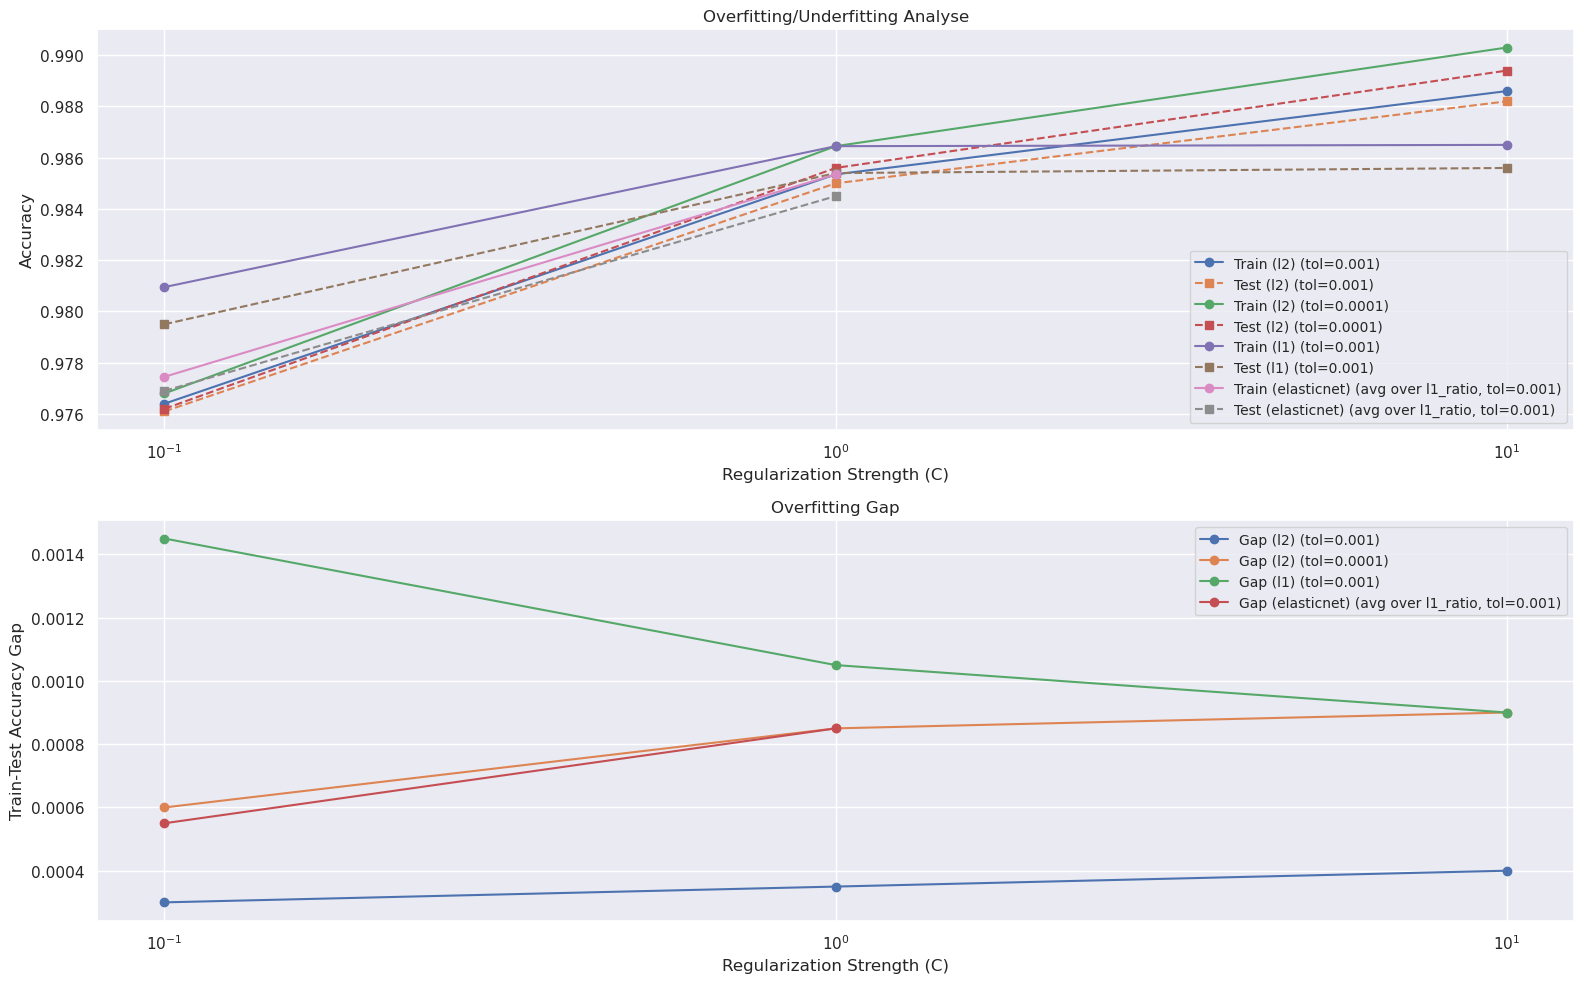

In [11]:
plt.figure(figsize=(16, 10))

penalties = results['param_classifier__penalty'].dropna().unique()
tols = results['param_classifier__tol'].dropna().unique()

# --- Plot 1: Train vs. Test Scores ---
ax1 = plt.subplot(2, 1, 1)
for penalty in penalties:
    for tol in tols:
        mask = (results['param_classifier__penalty'] == penalty) & (results['param_classifier__tol'] == tol)
        subset = results[mask].copy() 
        
        if penalty == 'elasticnet': 
            plot_data = subset.groupby('param_classifier__C').mean(numeric_only=True)
            label_suffix = f"(avg over l1_ratio, tol={tol})"
        else: 
            plot_data = subset.set_index('param_classifier__C')
            label_suffix = f"(tol={tol})"

        if not plot_data.empty:
            plot_data.sort_index(inplace=True)
            ax1.semilogx(plot_data.index, plot_data['mean_train_score'], 'o-', label=f'Train ({penalty}) {label_suffix}')
            ax1.semilogx(plot_data.index, plot_data['mean_test_score'], 's--', label=f'Test ({penalty}) {label_suffix}')

ax1.set_xlabel('Regularization Strength (C)')
ax1.set_ylabel('Accuracy')
ax1.set_title('Overfitting/Underfitting Analyse')
ax1.legend(loc='lower right', fontsize='small')

# --- Plot 2: Overfitting Gap ---
ax2 = plt.subplot(2, 1, 2)
for penalty in penalties:
    for tol in tols:
        mask = (results['param_classifier__penalty'] == penalty) & (results['param_classifier__tol'] == tol)
        subset = results[mask].copy()
        
        if penalty == 'elasticnet':
            plot_data = subset.groupby('param_classifier__C').mean(numeric_only=True)
            label_suffix = f"(avg over l1_ratio, tol={tol})"
        else:
            plot_data = subset.set_index('param_classifier__C')
            label_suffix = f"(tol={tol})"

        if not plot_data.empty:
            plot_data.sort_index(inplace=True)
            gap = plot_data['mean_train_score'] - plot_data['mean_test_score']
            ax2.semilogx(plot_data.index, gap, 'o-', label=f'Gap ({penalty}) {label_suffix}')

ax2.set_xlabel('Regularization Strength (C)')
ax2.set_ylabel('Train-Test Accuracy Gap')
ax2.set_title('Overfitting Gap')
ax2.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()

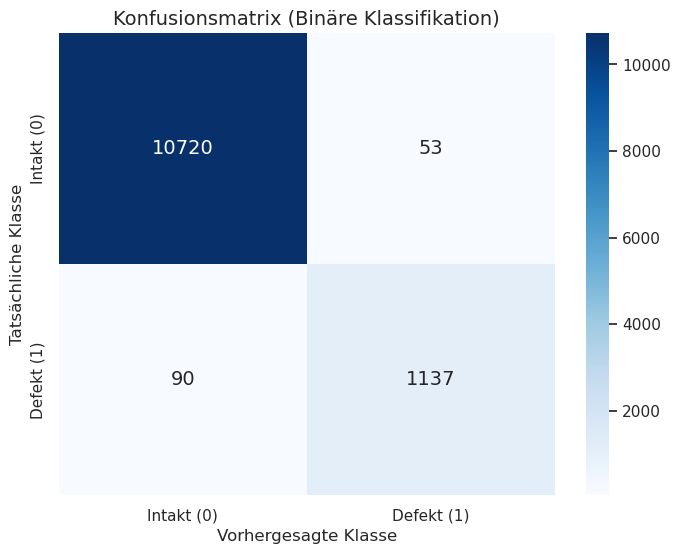

In [12]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Intakt (0)', 'Defekt (1)'], 
            yticklabels=['Intakt (0)', 'Defekt (1)'],
            annot_kws={"size": 14})

plt.title('Konfusionsmatrix (Binäre Klassifikation)', fontsize=14)
plt.xlabel('Vorhergesagte Klasse', fontsize=12)
plt.ylabel('Tatsächliche Klasse', fontsize=12)
plt.show()

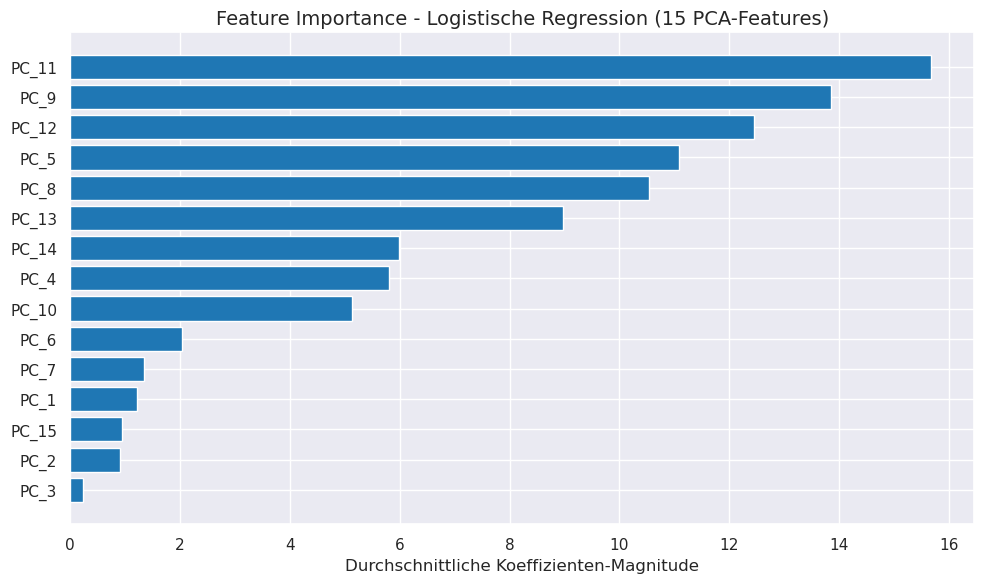

In [13]:
# Lade das spezifische Klassifikator-Modell aus der Pipeline
classifier = model.named_steps['classifier']

# Greife auf die Koeffizienten zu
importances = np.abs(classifier.coef_[0])
num_features = len(importances)

# Sortiere sie absteigend
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.barh(range(num_features), importances[indices][::-1], align='center', color='#1f77b4')
# Beschriftung mit PC_1 bis PC_15 anstelle von Wavelet-Features
plt.yticks(range(num_features), [f"PC_{i+1}" for i in indices][::-1])
plt.xlabel('Durchschnittliche Koeffizienten-Magnitude', fontsize=12)
plt.title(f'Feature Importance - Logistische Regression ({num_features} PCA-Features)', fontsize=14)
plt.tight_layout()
plt.show()

Berechne Lernkurve (auf einem Subsample von max 10.000 Pixeln zur Beschleunigung)...


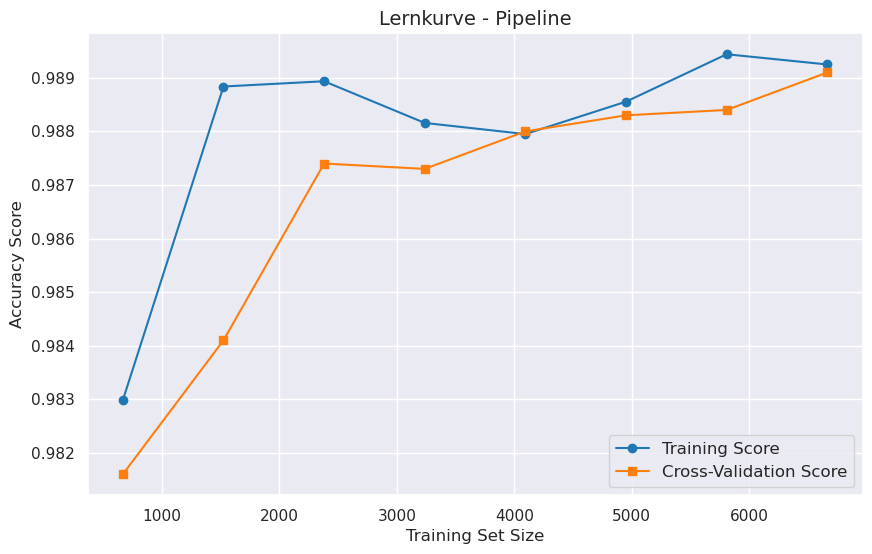

In [14]:
print("Berechne Lernkurve (auf einem Subsample von max 10.000 Pixeln zur Beschleunigung)...")

# Subsample für die Lernkurve nutzen
X_lc = X_train[:10000]
y_lc = y_train[:10000]

train_sizes, train_scores, test_scores = learning_curve(
    estimator=model, X=X_lc, y=y_lc,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=3, n_jobs=-1, scoring='accuracy'
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, color='tab:blue', marker='o', label='Training Score')
plt.plot(train_sizes, test_mean, color='tab:orange', marker='s', label='Cross-Validation Score')

plt.title('Lernkurve - Pipeline', fontsize=14)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.grid(True)
plt.show()